# Scenario 1 — Retail Inventory Analysis
**Lab:** Generative AI for Data Science · **Focus:** agentic prompting, generated code, refinement, validation, visualization

**Scenario provided:** Retail chain seeks stock turnover trends, slow-moving products, stockout warnings, and visualizations. Available fields: `product_id`, `category`, `stock_level`, `last_restock_date`, `sales_last_30_days`, `supplier_lead_time`, `unit_cost`.

**Data note:** No company dataset was supplied with the assignment. This notebook therefore runs on **clearly labeled synthetic example inventory** by default, and can read a real `retail_inventory.csv` with the same columns. The numeric results are illustrative, not real business findings.

## 1. Your Prompt — first iteration

> **Role:** Act as a senior retail analytics data scientist and Python engineer. **Task:** Develop a Jupyter-ready inventory analysis from a pandas DataFrame containing `product_id`, `category`, `stock_level`, `last_restock_date`, `sales_last_30_days`, `supplier_lead_time`, `unit_cost`. Calculate 30-day inventory movement/turnover, flag slow-moving SKUs, forecast days until a potential stockout using recent sales, and visualize actionable findings by category and risk. Use pandas, NumPy, and Matplotlib. Explain assumptions and show the output as readable tables and charts. Include explicit date conversions and comments.

**Why this prompt:** It establishes an expert role, exact input schema, business outputs, libraries, and desired report format, rather than requesting generic inventory code.

## 2. Generated Code — initial draft (retained for comparison, **not executed**)

```python
import pandas as pd

def first_draft_inventory(df):
    df = df.copy()
    df['last_restock_date'] = pd.to_datetime(df['last_restock_date'])
    df['days_since_restock'] = (pd.Timestamp.today() - df['last_restock_date']).dt.days
    df['turnover'] = df['sales_last_30_days'] / df['stock_level']
    df['days_to_stockout'] = df['stock_level'] / (df['sales_last_30_days'] / 30)
    df['slow_moving'] = df['sales_last_30_days'] < 3
    return df
```

**Review of initial code:** It is vulnerable to division by zero, does not check invalid or future restock dates, ignores supplier lead times, and labels `sales / current_stock` as inventory turnover even though **true turnover requires COGS and average historical inventory**. Using today's clock also makes the result irreproducible. We use this critique to refine the prompt.

## 3. Follow-up Prompts — improvement cycle

**Follow-up A (correctness):** “Refactor the draft to accept a fixed `as_of_date`, reject duplicates, invalid or future dates, negative stock, negative sales, invalid costs and lead times, and handle zero sales/zero stock without division errors. Define any turnover *proxy* honestly; do not call it an audited turnover rate unless historical average inventory is available.”

**Follow-up B (decision support):** “Add an explicit `days_of_supply` estimate using recent units sold per day, a `REORDER_NOW` classification when coverage is no more than supplier lead time, and a transparent slow-moving threshold. Produce three business-friendly charts with axes and titles; add executable assertions and docstrings.”

**Improvement rationale:** The initial generic solution is adequate for a small demonstration but unsafe for replenishment decisions. The refined code separates approximations from actual turnover, validates inputs, and generates operationally useful risk flags.

## 4. Final Solution — imports and example data

To use your own file, put `retail_inventory.csv` beside this notebook. The synthetic sample runs when no file exists. All date-based metrics use a fixed UTC date for reproducibility.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

AS_OF = pd.Timestamp('2026-11-25', tz='UTC')
source_path = Path('retail_inventory.csv')

if source_path.exists():
    inventory = pd.read_csv(source_path)
    print(f'Real file loaded: {source_path}')
else:
    inventory = pd.DataFrame([
        ('P100','Electronics',12,'2026-10-02',65,14,120.00),
        ('P101','Electronics',3,'2026-10-15',40,21,75.00),
        ('P102','Electronics',68,'2026-09-30',1,10,40.00),
        ('P103','Home',140,'2026-10-05',4,8,11.00),
        ('P104','Home',28,'2026-11-10',35,7,18.00),
        ('P105','Home',0,'2026-10-02',12,8,9.00),
        ('P106','Beauty',25,'2026-10-04',82,10,22.00),
        ('P107','Beauty',75,'2026-09-15',0,14,13.00),
        ('P108','Beauty',40,'2026-11-01',18,30,16.00),
        ('P109','Grocery',20,'2026-11-14',120,5,5.00),
        ('P110','Grocery',125,'2026-10-01',6,4,3.50),
        ('P111','Grocery',44,'2026-10-03',15,12,4.00),
        ('P112','Sports',45,'2026-09-01',3,20,28.00),
        ('P113','Sports',18,'2026-09-18',33,21,35.00),
    ], columns=['product_id','category','stock_level','last_restock_date',
                'sales_last_30_days','supplier_lead_time','unit_cost'])
    print('Synthetic example data loaded — not actual retailer data')

print(inventory.head(5).to_string(index=False))

Synthetic example data loaded — not actual retailer data
product_id    category  stock_level last_restock_date  sales_last_30_days  supplier_lead_time  unit_cost
      P100 Electronics           12        2026-10-02                  65                  14      120.0
      P101 Electronics            3        2026-10-15                  40                  21       75.0
      P102 Electronics           68        2026-09-30                   1                  10       40.0
      P103        Home          140        2026-10-05                   4                   8       11.0
      P104        Home           28        2026-11-10                  35                   7       18.0


In [ ]:
def analyze_inventory(df: pd.DataFrame, as_of_date: pd.Timestamp) -> pd.DataFrame:
    """Validate SKU snapshot and compute labeled replenishment estimates.

    Important: the turnover *proxy* assumes no receipts during the 30-day
    interval. Actual inventory turnover requires historic average inventory.
    """
    required = ['product_id','category','stock_level','last_restock_date',
                'sales_last_30_days','supplier_lead_time','unit_cost']
    missing = [col for col in required if col not in df]
    if missing:
        raise ValueError(f'Missing columns: {missing}')
    result = df[required].copy()
    result['product_id'] = result['product_id'].astype('string').str.strip()
    result['category'] = result['category'].astype('string').str.strip()
    if result['product_id'].isna().any() or result['product_id'].eq('').any():
        raise ValueError('Product ID cannot be missing or blank')
    if result['product_id'].duplicated().any():
        raise ValueError('Expected one snapshot row per unique product_id')
    if result['category'].isna().any() or result['category'].eq('').any():
        raise ValueError('Category cannot be missing or blank')

    for col in ['stock_level','sales_last_30_days','supplier_lead_time','unit_cost']:
        result[col] = pd.to_numeric(result[col], errors='coerce')
        if result[col].isna().any() or not np.isfinite(result[col].to_numpy()).all():
            raise ValueError(f'{col} must contain finite numeric values')
        if (result[col] < 0).any():
            raise ValueError(f'{col} cannot be negative')
    for col in ['stock_level','sales_last_30_days','supplier_lead_time']:
        if not np.equal(result[col], np.floor(result[col])).all():
            raise ValueError(f'{col} must contain non-negative integers')

    as_of = pd.Timestamp(as_of_date)
    if as_of.tzinfo is None:
        as_of = as_of.tz_localize('UTC')
    else:
        as_of = as_of.tz_convert('UTC')
    result['last_restock_date'] = pd.to_datetime(
        result['last_restock_date'], utc=True, errors='coerce')
    if result['last_restock_date'].isna().any():
        raise ValueError('last_restock_date must contain valid dates')
    if (result['last_restock_date'] > as_of).any():
        raise ValueError('Restock dates cannot be in the future')

    result['days_since_restock'] = (as_of - result['last_restock_date']).dt.days
    result['daily_units_sold_30d'] = result['sales_last_30_days'] / 30.0
    velocity = result['daily_units_sold_30d'].to_numpy(dtype=float)
    stock = result['stock_level'].to_numpy(dtype=float)
    result['days_of_supply'] = np.divide(stock, velocity,
        out=np.full(len(result), np.inf), where=velocity > 0)
    # Zero inventory always means out-of-stock, even if sales are also zero.
    result.loc[result['stock_level'].eq(0), 'days_of_supply'] = 0.0
    result['slow_moving'] = (result['stock_level'] > 0) & (
        (result['sales_last_30_days'] <= 2) | (result['days_of_supply'] >= 180))
    result['reorder_units_14d_buffer'] = np.maximum(0, np.ceil(
        result['daily_units_sold_30d'] * (result['supplier_lead_time'] + 14)
        - result['stock_level'])).astype(int)
    result['inventory_value'] = result['stock_level'] * result['unit_cost']
    result['replenishment_status'] = np.select([
        result['stock_level'].eq(0),
        result['days_of_supply'].le(result['supplier_lead_time']),
        result['days_of_supply'].le(result['supplier_lead_time'] + 7),
        result['slow_moving'],
    ], ['OUT_OF_STOCK','REORDER_NOW','WATCH','SLOW_MOVING'], default='OK')

    # Illustrative *estimate* only: assumes opening stock = ending stock + sales,
    # i.e., no receipts, returns, or losses during the last 30 days.
    estimated_avg_units = result['stock_level'] + result['sales_last_30_days'] / 2
    result['estimated_turnover_30d_proxy'] = np.divide(
        result['sales_last_30_days'], estimated_avg_units,
        out=np.zeros(len(result), dtype=float), where=estimated_avg_units > 0)
    result['restocked_within_30d'] = result['days_since_restock'] < 30
    result['proxy_assumption_violated_or_unknown'] = result['restocked_within_30d']
    return result

analysis = analyze_inventory(inventory, AS_OF)
print(analysis[['product_id','category','estimated_turnover_30d_proxy',
  'days_of_supply','replenishment_status','slow_moving']].to_string(index=False))

product_id    category  estimated_turnover_30d_proxy  days_of_supply replenishment_status  slow_moving
      P100 Electronics                      1.460674        5.538462          REORDER_NOW        False
      P101 Electronics                      1.739130        2.250000          REORDER_NOW        False
      P102 Electronics                      0.014599     2040.000000          SLOW_MOVING         True
      P103        Home                      0.028169     1050.000000          SLOW_MOVING         True
      P104        Home                      0.769231       24.000000                   OK        False
      P105        Home                      2.000000        0.000000         OUT_OF_STOCK        False
      P106      Beauty                      1.242424        9.146341          REORDER_NOW        False
      P107      Beauty                      0.000000             inf          SLOW_MOVING         True
      P108      Beauty                      0.367347       66.666667     

### Interpretation: turnover versus stock coverage

**Audited inventory turnover** = cost of goods sold ÷ average inventory value for the same period. The supplied snapshot has no beginning stock, receipts, returns, or historic average inventory, so **audited turnover cannot be calculated**. Here, `estimated_turnover_30d_proxy = units_sold / (current_stock + 0.5 × units_sold)` is an illustrative estimate assuming no replenishments or losses, and is explicitly flagged when a restock occurred in the last 30 days. Use the *days of supply* and supplier lead-time comparisons for preliminary stockout screening—not as a probabilistic forecast of demand.

In [ ]:
# Assertions test successful calculations and failure cases.
assert set(['OUT_OF_STOCK','REORDER_NOW']).issubset(set(analysis['replenishment_status']))
assert (analysis['estimated_turnover_30d_proxy'] >= 0).all()
assert analysis.loc[analysis.product_id.eq('P105'), 'days_of_supply'].item() == 0
assert np.isinf(analysis.loc[analysis.product_id.eq('P107'), 'days_of_supply'].item())
assert analysis['reorder_units_14d_buffer'].ge(0).all()
try:
    invalid = inventory.copy()
    invalid.loc[0, 'supplier_lead_time'] = -1
    analyze_inventory(invalid, AS_OF)
    raise AssertionError('Validation should have rejected negative lead time')
except ValueError:
    pass
print('Inventory analysis tests passed')

Inventory analysis tests passed


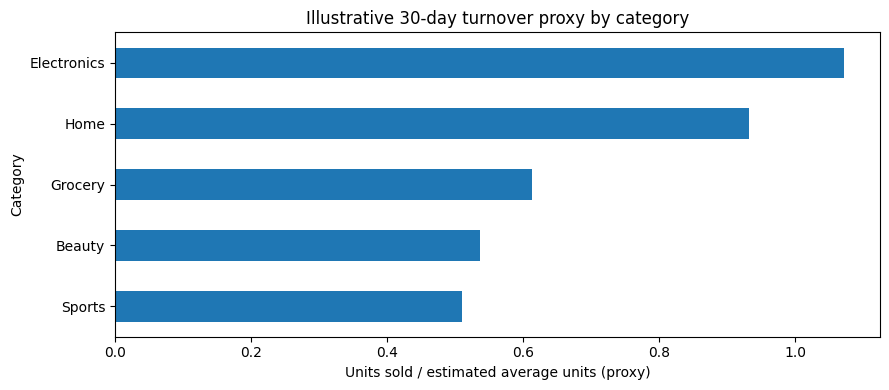

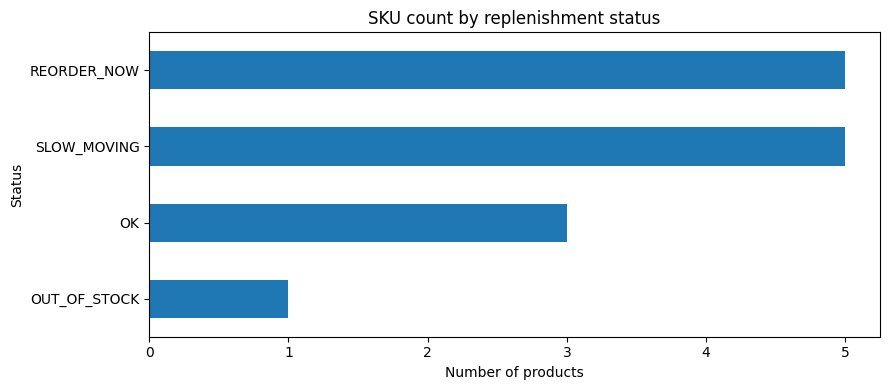

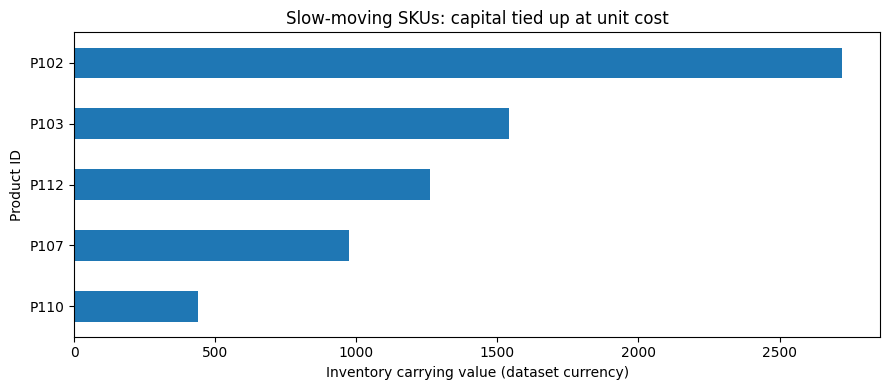

In [ ]:
# Three management-ready visual summaries.
category = analysis.groupby('category', as_index=False).agg(
    avg_proxy_turnover=('estimated_turnover_30d_proxy','mean'),
    inventory_value=('inventory_value','sum'))
ax = category.sort_values('avg_proxy_turnover').plot.barh(
    x='category', y='avg_proxy_turnover', legend=False, figsize=(9,4))
ax.set_title('Illustrative 30-day turnover proxy by category')
ax.set_xlabel('Units sold / estimated average units (proxy)')
ax.set_ylabel('Category')
plt.tight_layout(); plt.show()

status = analysis['replenishment_status'].value_counts().sort_values()
ax = status.plot.barh(figsize=(9,4))
ax.set_title('SKU count by replenishment status')
ax.set_xlabel('Number of products')
ax.set_ylabel('Status')
plt.tight_layout(); plt.show()

slow = analysis[analysis['slow_moving']].nlargest(8, 'inventory_value')
if not slow.empty:
    ax = slow.sort_values('inventory_value').plot.barh(
        x='product_id', y='inventory_value', legend=False, figsize=(9,4))
    ax.set_title('Slow-moving SKUs: capital tied up at unit cost')
    ax.set_xlabel('Inventory carrying value (dataset currency)')
    ax.set_ylabel('Product ID')
    plt.tight_layout(); plt.show()

## 5. Results and Discussion

**1. How did different prompts handle date calculations?** The initial prompt produced a current-date calculation with `pd.Timestamp.today()`, which is not reproducible and does not validate malformed or future restock dates. The refined prompt required a fixed `as_of_date`, UTC-aware parsing with `pd.to_datetime(..., utc=True)`, explicit day differences, and validation. This made time-based outputs consistent and auditable.

**2. What visualization approaches were suggested?** The first request suggested basic inventory charts; the refined solution uses a horizontal bar chart of category-level turnover *proxies*, a count of replenishment status categories, and a slow-moving stock-value ranking. These match three distinct decisions: category performance, urgent reorder prioritization, and excess inventory exposure. Axes, units, and limitations are labeled.

**3. How was error handling implemented?** The first generated draft lacked input validation and would divide by zero when stock or sales were zero. The final code checks required fields, duplicate IDs, numeric validity, negative quantities, future dates, and integer-like quantities. It safely handles zero sales as infinite supply and zero stock as immediate stockout. Executable assertions test expected behavior and a deliberately invalid case.

**Peer discussion prompt:** Should replenishment be based on a simple 30-day sales velocity, or should we use seasonality and demand uncertainty to estimate safety stock? How would our input requirements change?

**Reflection:** Prompt specificity improved reproducibility, error handling, and business interpretability. A key limit remains: the supplied columns do not permit a reliable historical turnover measure or a statistically calibrated stockout probability.